# 01. Сначала смотрим на данные

Работаю с двумя открытыми наборами CIMMYT.

**Пшеница** — данные из Crossa et al. (2010, *Genetics* 186:713–724,
doi:10.1534/genetics.110.118521), лежат внутри R-пакета BGLR
(github.com/gdlc/BGLR-R, файл `wheat.RData`):

- `X` — 599 линий × 1279 маркеров DArT, закодированы 0/1;
- `Y` — урожайность зерна в 4 мега-средах, уже стандартизирована внутри среды;
- `A` — матрица родства по родословной;
- `sets` — разбиение на 10 фолдов из исходной статьи.

Чистку авторы сделали за нас: маркеры с MAF < 0.05 выкинуты, пропуски
заимпутированы.

**Кукуруза** — Cuevas et al. (2017, *G3* 7:1833–1847,
doi:10.1534/g3.117.300095), скачана с data.cimmyt.org (hdl:11529/10907):
309 DH-линий в трёх средах (EBU, KAK, KTI), признаки Yield / ASI / PH.
Сырых маркеров в открытом доступе нет (у CIMMYT они под запросом), зато
есть готовая матрица родства `G` — её хватит для GBLUP в ноутбуке 06.

Пшеницу беру под маркерные модели, потому что это ровно те данные, на
которых Crossa et al. (2010) сравнивали Bayesian LASSO и RKHS: маленькие,
чистые, с ними удобно разбираться.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# проект импортируется и из корня, и из папки notebooks/
for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / "gp_models" / "__init__.py").exists():
        sys.path.insert(0, str(cand))
        PROJECT = cand
        break

import gp_models as gpm
from gp_models import data, preprocessing as pp

matplotlib.rcParams["font.family"] = ["Liberation Sans", "Arimo", "DejaVu Sans"]
matplotlib.rcParams["svg.fonttype"] = "none"
FIGDIR = PROJECT / "figures"
FIGDIR.mkdir(exist_ok=True)
%matplotlib inline


In [2]:
w = data.load_wheat()
X, Y, A, sets = w["X"], w["Y"], w["A"], w["sets"]
print("X:", X.shape, "| значения:", np.unique(X))
print("Y:", Y.shape, "| среды:", w["env_names"])
print("A:", A.shape, "| sets: фолды", np.unique(sets))

X: (599, 1279) | значения: [0. 1.]
Y: (599, 4) | среды: ['1', '2', '4', '5']
A: (599, 599) | sets: фолды [ 1  2  3  4  5  6  7  8  9 10]


## Частоты аллелей

DArT — доминантные маркеры (0/1: есть сигнал / нет сигнала). Перед тем как
что-то считать, смотрю на частоты: почти мономорфные маркеры (MAF около
нуля) почти не несут информации и портят сходимость, поэтому в статьях их
выкидывают фильтром MAF ≥ 0.05. Здесь это уже сделано авторами, но
проверить не мешает.

c = 2*sum p(1-p) = 426.3
MAF: min=0.008, медиана=0.24, max=0.50


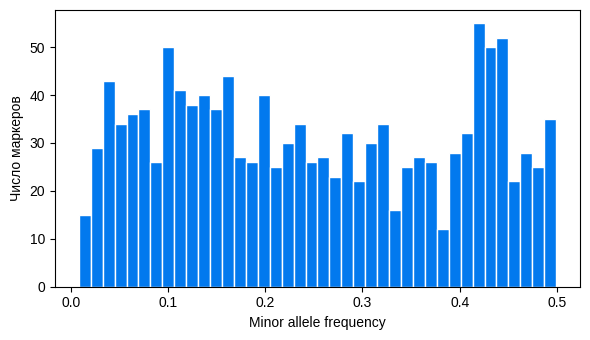

In [3]:
Z, p, c = pp.center_markers(X)
maf = np.minimum(p, 1 - p)
print(f"c = 2*sum p(1-p) = {c:.1f}")
print(f"MAF: min={maf.min():.3f}, медиана={np.median(maf):.2f}, max={maf.max():.2f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(maf, bins=40, color="#0279EE", edgecolor="white")
ax.set_xlabel("Minor allele frequency")
ax.set_ylabel("Число маркеров")
plt.tight_layout(); plt.show()

## Фенотипы

Y идёт уже центрированным и стандартизированным внутри каждой среды (в
таком виде его раздают с BGLR). Интересно посмотреть, как коррелирует
урожайность между средами: если линии ранжируются в разных средах
по-разному, переносить прогноз из среды в среду будет тяжело.

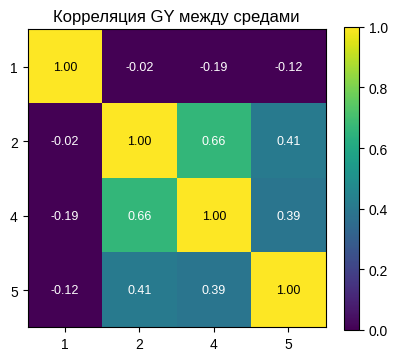

In [4]:
corrY = np.corrcoef(Y.T)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(corrY, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(4), w["env_names"]); ax.set_yticks(range(4), w["env_names"])
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corrY[i,j]:.2f}", ha="center", va="center",
                color="white" if corrY[i,j] < 0.7 else "black", fontsize=9)
ax.set_title("Корреляция GY между средами")
fig.colorbar(im); plt.tight_layout(); plt.show()

## Матрица родства ВанРадена

$$G = \frac{ZZ^{\prime}}{c}, \qquad Z_{ij} = X_{ij} - 2p_j, \qquad c = 2\sum_j p_j(1-p_j)$$

По диагонали примерно 1 + F (у линий близко к 1), вне диагонали —
насколько пара линий похожа генетически. Рисую тепловую карту, чтобы
увидеть, есть ли внутри популяции субструктура (такие же картинки у
Crossa et al., 2014). Рядом для сравнения — родословная матрица A.

G: diag mean=0.50 (sd 0.08), off-diag mean=-0.001


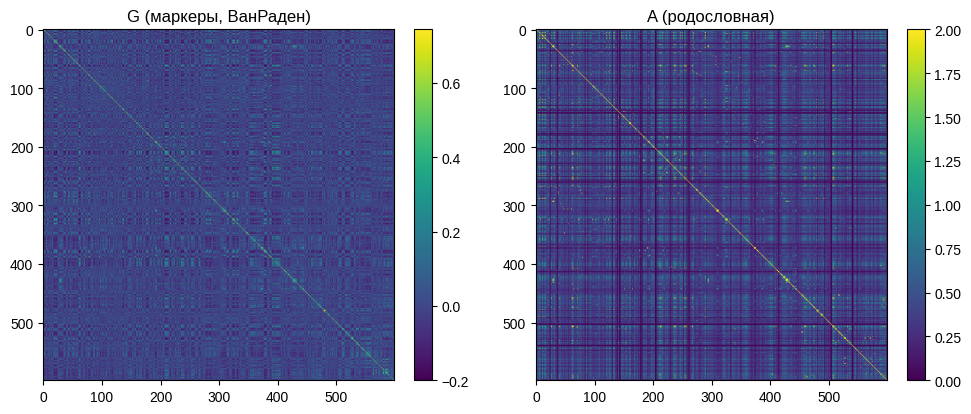

In [5]:
G = Z @ Z.T / c
print(f"G: diag mean={np.diag(G).mean():.2f} (sd {np.diag(G).std():.2f}), "
      f"off-diag mean={G[np.triu_indices(599,1)].mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, M, t in [(axes[0], G, "G (маркеры, ВанРаден)"), (axes[1], A, "A (родословная)")]:
    im = ax.imshow(M, cmap="viridis")
    ax.set_title(t); fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(FIGDIR / "wheat_G_and_A.png", dpi=150)
plt.savefig(FIGDIR / "wheat_G_and_A.svg")
plt.show()

## Кукуруза

309 DH-линий, три среды, по одному повторению на линию в каждой. Матрицу
G посчитали авторы из GBS-маркеров. Диагональ у неё ~0.2, а не ~1, как у
ванраденовской, — видимо, своя нормировка. Для прогноза это не важно
(масштаб матрицы просто поглощается σ²_g), а вот к интерпретации h²
вернёмся в ноутбуке 06.

    Yield               ASI                PH            
     mean   std count  mean   std count  mean   std count
Env                                                      
EBU  6.49  0.92   309  1.63  0.71   309  2.33  0.13   309
KAK  4.99  0.71   309  1.06  1.09   309  2.03  0.12   309
KTI  6.12  0.97   309  2.32  0.81   309  2.35  0.15   309

G: (309, 309), diag mean=0.208, off-diag mean=0.069


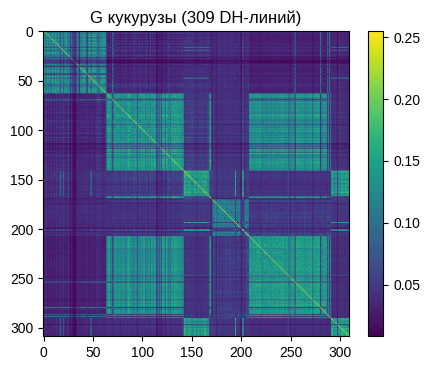

In [6]:
m = data.load_maize()
ph, Gm = m["pheno"], m["G"]
print(ph.groupby("Env")[["Yield", "ASI", "PH"]].agg(["mean", "std", "count"]).round(2))
print(f"\nG: {Gm.shape}, diag mean={np.diag(Gm).mean():.3f}, "
      f"off-diag mean={Gm[np.triu_indices(Gm.shape[0],1)].mean():.3f}")

fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = ax.imshow(Gm, cmap="viridis")
ax.set_title("G кукурузы (309 DH-линий)")
fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

## Что дальше

- **02** — RR-BLUP в замкнутой форме и проверка, что GBLUP даёт то же самое;
- **03** — та же модель по-байесовски: гиббс-сэмплер (BRR);
- **04** — BayesA: у каждого маркера своя дисперсия;
- **05** — кросс-валидация 70/30 × 50, сравнение трёх моделей;
- **06** — GBLUP на кукурузе CIMMYT (на матрице G выше).